# 🚀 STAGE 2: Quantization Compression of Arabic Legal LLM

## Paper 2: Extreme Compression of Arabic Legal LLMs

**Teacher Model:** FANAR-9B + SFT (Stage 1 Best - 77.60% Knowledge)

**Compression Methods (Quantization Focus):**
1. **INT8 Quantization** (BitsAndBytes) - 50% size reduction
2. **INT4 Quantization** (BitsAndBytes NF4) - 75% size reduction
3. **GPTQ INT4** - Optimized post-training quantization
4. **AWQ INT4** - Activation-aware weight quantization

**Evaluation:** Both With Context (RC) and Without Context (Knowledge)

**Goal:** Find Pareto frontier (size vs performance)

**Expected Timeline:** 1-2 days, ~$5-10 cost

## 📦 CELL 1: Install Dependencies

In [1]:
import sys, os

# Fix temp directory issue
os.environ["TMPDIR"] = "/tmp"

# Upgrade build tools first
#!{sys.executable} -m pip install -U pip setuptools wheel

# Install PyTorch first
#!{sys.executable} -m pip install -U torch torchvision torchaudio

# Core HF stack
!{sys.executable} -m pip install -U transformers accelerate bitsandbytes peft datasets

# GPTQ dependencies AFTER torch
!{sys.executable} -m pip install -U optimum
!{sys.executable} -m pip install -U auto-gptq --extra-index-url https://huggingface.github.io/autogptq-index/whl/cu121/

# Evaluation
!{sys.executable} -m pip install -U nltk pandas tqdm matplotlib seaborn
!{sys.executable} -m pip install -U rouge-score --no-build-isolation

print("✅ Install commands finished")

Defaulting to user installation because normal site-packages is not writeable


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 57.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 721.1/721.1 kB 14.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 39.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 89.1 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.2/532.2 MB 84.4 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 90.9 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 95.6 MB/s  0:00:01m0:00:0100:01


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 94.5 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 90.4 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.7/197.7 MB 94.6 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 54.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 88.6 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 84.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 93.4 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 35.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 97.6 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 24.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 MB 91.2 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/200.9 MB 96.2 MB/s

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://huggingface.github.io/autogptq-index/whl/cu121/


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.5/23.5 MB 89.0 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 84.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.4 MB/s  0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [auto-gptq]/4 [auto-gptq]
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 21.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 66.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 79.2 MB/s  0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 2/4 [nltk]  WARNING: The script nltk is installed in '/home/pmp6991/.local/bin' which is not on PATH.
  Con

✅ Install commands finished


In [1]:
!/miniconda/envs/ml-data-science-kernel-py311/bin/python -m pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.5.1+cu121
Uninstalling torch-2.5.1+cu121:
  Successfully uninstalled torch-2.5.1+cu121


In [2]:
!/miniconda/envs/ml-data-science-kernel-py311/bin/python -m pip install --no-cache-dir torch==2.5.1+cu121 --index-url https://download.pytorch.org/whl/cu121

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.5/780.5 MB 118.3 MB/s  0:00:0600:0100:01
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import torch

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.12.1+cu130
CUDA available: True
CUDA version: 13.0
GPU: NVIDIA A100-PCIE-40GB


In [3]:
!pip install -q autoawq

In [4]:
import torch
import transformers
import bitsandbytes
import peft

print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Transformers:", transformers.__version__)

/home/pmp6991/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/pmp6991/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Torch: 2.12.1+cu130
CUDA: True
Transformers: 5.12.1


## 📚 CELL 2: Imports and Configuration

In [25]:
import os
import json
import re
import gc
import time
import random
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from collections import Counter, defaultdict
from datetime import datetime

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import PeftModel
from rouge_score import rouge_scorer
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Set seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

class Config:
    # Paths
    BASE_MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"
    SFT_LORA_PATH = "./models_QWENlegal_stage1/exp_d_cpt_sft"  # Stage 1 best model
    
    # Output dirs
    RESULTS_DIR = "./results_qwen_stage2"
    MODELS_DIR = "./models_qwen_stage2"
    DATA_DIR = "./results_fanar_stage1"  # Where Stage 1 splits are
    
    # Evaluation
    EVAL_SAMPLE_SIZE = 500  # Same as Stage 1 for consistency
    
    # Generation
    MAX_NEW_TOKENS = 10  # For MCQ
    TEMPERATURE = 0.1
    TOP_P = 0.9
    
    SEED = 42

for d in [Config.RESULTS_DIR, Config.MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"✅ Configuration set")
print(f"   Teacher: {Config.SFT_LORA_PATH}")
print(f"   Results: {Config.RESULTS_DIR}")
print(f"\n✅ GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'}")

✅ Configuration set
   Teacher: ./models_QWENlegal_stage1/exp_d_cpt_sft
   Results: ./results_qwen_stage2

✅ GPU: NVIDIA A100-PCIE-40GB


## 📂 CELL 3: Load Evaluation Data from Stage 1

In [26]:
# Load the same splits used in Stage 1
with open(f"{Config.DATA_DIR}/mcq_eval.json", 'r', encoding='utf-8') as f:
    mcq_eval = json.load(f)

with open(f"{Config.DATA_DIR}/qa_eval.json", 'r', encoding='utf-8') as f:
    qa_eval = json.load(f)

# Use same 500 sample as Stage 1 for direct comparison
mcq_eval_sample = mcq_eval[:Config.EVAL_SAMPLE_SIZE]

print(f"✅ Loaded evaluation data:")
print(f"   MCQ Eval: {len(mcq_eval)} (using {len(mcq_eval_sample)} for evaluation)")
print(f"   QA Eval:  {len(qa_eval)}")

✅ Loaded evaluation data:
   MCQ Eval: 2113 (using 500 for evaluation)
   QA Eval:  200


## 🔧 CELL 4: Define Evaluation Functions

In [27]:
def format_mcq_with_context(item):
    """With context - reading comprehension setting"""
    options = item['options']
    return f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بناءً على النص القانوني المرجعي.

النص القانوني المرجعي: {item.get('context', '')}

السؤال: {item['question']}

الخيارات:
A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

اختر الإجابة الصحيحة (A أو B أو C أو D فقط):
الإجابة:"""

def format_mcq_without_context(item):
    """Without context - knowledge-based setting"""
    options = item['options']
    return f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بناءً على معرفتك بالأنظمة السعودية.

السؤال: {item['question']}

الخيارات:
A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

اختر الإجابة الصحيحة (A أو B أو C أو D فقط):
الإجابة:"""

def extract_mcq_answer(response):
    """Extract A, B, C, D from response"""
    response = response.strip().upper()
    for char in response[:50]:
        if char in ['A', 'B', 'C', 'D']:
            return char
    ar_to_en = {'أ': 'A', 'ب': 'B', 'ج': 'C', 'د': 'D'}
    for ar, en in ar_to_en.items():
        if ar in response[:20]:
            return en
    return 'INVALID'

def generate_answer(model, tokenizer, prompt, max_new_tokens=10):
    """Generate answer from any model"""
    inputs = tokenizer(
        prompt, 
        return_tensors="pt", 
        truncation=True, 
        max_length=1500
    ).to(model.device)
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            temperature=Config.TEMPERATURE,
            top_p=Config.TOP_P,
            do_sample=True,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    
    response = tokenizer.decode(
        outputs[0][inputs['input_ids'].shape[1]:],
        skip_special_tokens=True
    )
    return response.strip()

def evaluate_dual_setting(model, tokenizer, eval_data, model_name="model"):
    """Evaluate model in BOTH settings (with/without context)"""
    
    print(f"\n📊 Evaluating: {model_name}")
    
    # WITH CONTEXT
    correct_with = 0
    start_time = time.time()
    
    for item in tqdm(eval_data, desc=f"{model_name} (with ctx)"):
        prompt = format_mcq_with_context(item)
        response = generate_answer(model, tokenizer, prompt)
        predicted = extract_mcq_answer(response)
        if predicted == item['correct_answer']:
            correct_with += 1
    
    time_with = time.time() - start_time
    
    # WITHOUT CONTEXT
    correct_without = 0
    start_time = time.time()
    
    for item in tqdm(eval_data, desc=f"{model_name} (no ctx)"):
        prompt = format_mcq_without_context(item)
        response = generate_answer(model, tokenizer, prompt)
        predicted = extract_mcq_answer(response)
        if predicted == item['correct_answer']:
            correct_without += 1
    
    time_without = time.time() - start_time
    
    accuracy_with = correct_with / len(eval_data) * 100
    accuracy_without = correct_without / len(eval_data) * 100
    
    return {
        'model_name': model_name,
        'with_context': {
            'accuracy': accuracy_with,
            'correct': correct_with,
            'total': len(eval_data),
            'time_seconds': time_with
        },
        'without_context': {
            'accuracy': accuracy_without,
            'correct': correct_without,
            'total': len(eval_data),
            'time_seconds': time_without
        },
        'reading_skill': accuracy_with - accuracy_without
    }

def get_model_size_info(model):
    """Calculate model size in different metrics"""
    total_params = sum(p.numel() for p in model.parameters())
    
    # Memory size
    if hasattr(model, 'get_memory_footprint'):
        memory_mb = model.get_memory_footprint() / (1024 ** 2)
    else:
        # Estimate based on dtype
        memory_mb = 0
        for p in model.parameters():
            if p.dtype == torch.float32:
                memory_mb += p.numel() * 4
            elif p.dtype == torch.float16 or p.dtype == torch.bfloat16:
                memory_mb += p.numel() * 2
            elif p.dtype == torch.int8:
                memory_mb += p.numel() * 1
            else:
                memory_mb += p.numel() * 0.5  # 4-bit
        memory_mb = memory_mb / (1024 ** 2)
    
    return {
        'total_params': total_params,
        'total_params_billions': total_params / 1e9,
        'memory_mb': memory_mb,
        'memory_gb': memory_mb / 1024
    }

def cleanup_memory():
    """Free GPU memory"""
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        print(f"   GPU Memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")

print("✅ Evaluation functions defined")

✅ Evaluation functions defined


## 🏆 CELL 5: Load Teacher Model (SFT) and Get Baseline

Load the SFT model and merge LoRA weights for use as base for quantization

In [ ]:
#from huggingface_hub import login

#login("")

In [29]:
print("📥 Loading Teacher Model (QWEN-7B-Chat + SFT)...")

tokenizer = AutoTokenizer.from_pretrained(
    Config.BASE_MODEL_NAME,
    trust_remote_code=True,
    padding_side="left"
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load base in BF16 (full precision baseline)
model_base = AutoModelForCausalLM.from_pretrained(
    Config.BASE_MODEL_NAME,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

# Apply SFT LoRA weights
teacher_model = PeftModel.from_pretrained(model_base, Config.SFT_LORA_PATH)
teacher_model.eval()

# Merge LoRA into base for clean model
teacher_model = teacher_model.merge_and_unload()

# Save merged model for use in quantization
MERGED_MODEL_PATH = f"{Config.MODELS_DIR}/teacher_sft_merged"
teacher_model.save_pretrained(MERGED_MODEL_PATH)
tokenizer.save_pretrained(MERGED_MODEL_PATH)

print(f"✅ Teacher model loaded and merged")
print(f"   Saved to: {MERGED_MODEL_PATH}")

# Get baseline size info
baseline_info = get_model_size_info(teacher_model)
print(f"\n📊 Teacher (BF16) Stats:")
print(f"   Parameters: {baseline_info['total_params_billions']:.2f}B")
print(f"   Memory: {baseline_info['memory_gb']:.2f} GB")

📥 Loading Teacher Model (QWEN-7B-Chat + SFT)...


Writing model shards: 100%|██████████| 1/1 [00:14<00:00, 14.76s/it]

✅ Teacher model loaded and merged
   Saved to: ./models_qwen_stage2/teacher_sft_merged

📊 Teacher (BF16) Stats:
   Parameters: 7.62B
   Memory: 14.19 GB


## 📊 CELL 6: Evaluate Baseline (BF16 Teacher)

In [30]:
print("="*70)
print("🏆 BASELINE: Teacher SFT (BF16 - No Quantization)")
print("="*70)

baseline_results = evaluate_dual_setting(
    teacher_model, tokenizer, mcq_eval_sample, 
    model_name="BF16_Teacher"
)
baseline_results['size_info'] = baseline_info

print(f"\n📊 BF16 BASELINE RESULTS:")
print(f"   With Context:    {baseline_results['with_context']['accuracy']:.2f}%")
print(f"   Without Context: {baseline_results['without_context']['accuracy']:.2f}%")
print(f"   Memory: {baseline_info['memory_gb']:.2f} GB")

# Save
with open(f"{Config.RESULTS_DIR}/baseline_bf16.json", 'w') as f:
    json.dump(baseline_results, f, indent=2, default=str)

print("\n✅ Baseline complete!")

🏆 BASELINE: Teacher SFT (BF16 - No Quantization)

📊 Evaluating: BF16_Teacher


BF16_Teacher (no ctx): 100%|██████████| 500/500 [02:00<00:00,  4.16it/s]


📊 BF16 BASELINE RESULTS:
   With Context:    98.80%
   Without Context: 79.80%
   Memory: 14.19 GB

✅ Baseline complete!


## 🧹 CELL 7: Clean Memory

In [31]:
del teacher_model, model_base
cleanup_memory()

   GPU Memory: 1.28 GB


## 🔬 CELL 8: EXPERIMENT 1 - INT8 Quantization (BitsAndBytes)

**Method:** Load model in 8-bit using bitsandbytes
**Compression:** ~50% (BF16: 18GB → INT8: 9GB)

In [32]:
print("="*70)
print("🔬 EXPERIMENT 1: INT8 Quantization")
print("="*70)

# Load in INT8
bnb_int8_config = BitsAndBytesConfig(
    load_in_8bit=True,
    llm_int8_threshold=6.0,
)

print("📥 Loading model in INT8...")
model_int8 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_int8_config,
    device_map="auto",
    trust_remote_code=True,
)
model_int8.eval()

# Get size info
int8_info = get_model_size_info(model_int8)
print(f"\n📊 INT8 Model Stats:")
print(f"   Parameters: {int8_info['total_params_billions']:.2f}B")
print(f"   Memory: {int8_info['memory_gb']:.2f} GB")
print(f"   Compression: {(1 - int8_info['memory_gb']/baseline_info['memory_gb'])*100:.1f}%")

# Evaluate
int8_results = evaluate_dual_setting(
    model_int8, tokenizer, mcq_eval_sample,
    model_name="INT8_BNB"
)
int8_results['size_info'] = int8_info
int8_results['compression_ratio'] = int8_info['memory_gb'] / baseline_info['memory_gb']

# Save
with open(f"{Config.RESULTS_DIR}/exp1_int8.json", 'w') as f:
    json.dump(int8_results, f, indent=2, default=str)

print(f"\n📊 INT8 RESULTS:")
print(f"   With Context:    {int8_results['with_context']['accuracy']:.2f}% (vs BF16: {baseline_results['with_context']['accuracy']:.2f}%)")
print(f"   Without Context: {int8_results['without_context']['accuracy']:.2f}% (vs BF16: {baseline_results['without_context']['accuracy']:.2f}%)")
print(f"   Memory: {int8_info['memory_gb']:.2f} GB ({(1 - int8_info['memory_gb']/baseline_info['memory_gb'])*100:.1f}% reduction)")

print("\n✅ INT8 evaluation complete!")

🔬 EXPERIMENT 1: INT8 Quantization
📥 Loading model in INT8...


Loading weights: 100%|██████████| 339/339 [00:54<00:00,  6.24it/s]



📊 INT8 Model Stats:
   Parameters: 7.62B
   Memory: 8.11 GB
   Compression: 42.8%

📊 Evaluating: INT8_BNB


INT8_BNB (no ctx): 100%|██████████| 500/500 [09:52<00:00,  1.18s/it]


📊 INT8 RESULTS:
   With Context:    98.80% (vs BF16: 98.80%)
   Without Context: 77.80% (vs BF16: 79.80%)
   Memory: 8.11 GB (42.8% reduction)

✅ INT8 evaluation complete!


## 🧹 CELL 9: Clean Memory

In [33]:
del model_int8
cleanup_memory()

   GPU Memory: 1.28 GB


## 🔬 CELL 10: EXPERIMENT 2 - INT4 Quantization (BitsAndBytes NF4)

**Method:** 4-bit NormalFloat quantization
**Compression:** ~75% (BF16: 18GB → INT4: 4.5GB)

In [34]:
print("="*70)
print("🔬 EXPERIMENT 2: INT4 NF4 Quantization")
print("="*70)

bnb_int4_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

print("📥 Loading model in INT4 NF4...")
model_int4 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_int4_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)
model_int4.eval()

int4_info = get_model_size_info(model_int4)
print(f"\n📊 INT4 Model Stats:")
print(f"   Parameters: {int4_info['total_params_billions']:.2f}B")
print(f"   Memory: {int4_info['memory_gb']:.2f} GB")
print(f"   Compression: {(1 - int4_info['memory_gb']/baseline_info['memory_gb'])*100:.1f}%")

# Evaluate
int4_results = evaluate_dual_setting(
    model_int4, tokenizer, mcq_eval_sample,
    model_name="INT4_NF4"
)
int4_results['size_info'] = int4_info
int4_results['compression_ratio'] = int4_info['memory_gb'] / baseline_info['memory_gb']

with open(f"{Config.RESULTS_DIR}/exp2_int4_nf4.json", 'w') as f:
    json.dump(int4_results, f, indent=2, default=str)

print(f"\n📊 INT4 NF4 RESULTS:")
print(f"   With Context:    {int4_results['with_context']['accuracy']:.2f}% (vs BF16: {baseline_results['with_context']['accuracy']:.2f}%)")
print(f"   Without Context: {int4_results['without_context']['accuracy']:.2f}% (vs BF16: {baseline_results['without_context']['accuracy']:.2f}%)")
print(f"   Memory: {int4_info['memory_gb']:.2f} GB ({(1 - int4_info['memory_gb']/baseline_info['memory_gb'])*100:.1f}% reduction)")

print("\n✅ INT4 NF4 evaluation complete!")

🔬 EXPERIMENT 2: INT4 NF4 Quantization
📥 Loading model in INT4 NF4...


Loading weights: 100%|██████████| 339/339 [00:49<00:00,  6.84it/s]



📊 INT4 Model Stats:
   Parameters: 4.35B
   Memory: 5.07 GB
   Compression: 64.3%

📊 Evaluating: INT4_NF4


INT4_NF4 (no ctx): 100%|██████████| 500/500 [03:57<00:00,  2.11it/s]


📊 INT4 NF4 RESULTS:
   With Context:    98.60% (vs BF16: 98.80%)
   Without Context: 77.80% (vs BF16: 79.80%)
   Memory: 5.07 GB (64.3% reduction)

✅ INT4 NF4 evaluation complete!


## 🧹 CELL 11: Clean Memory

In [35]:
del model_int4
cleanup_memory()

   GPU Memory: 1.28 GB


## 🔬 CELL 12: EXPERIMENT 3 - INT4 FP4 Quantization

**Method:** 4-bit FloatPoint quantization (alternative to NF4)
**Compression:** Same as NF4 (~75%) but different precision

In [36]:
print("="*70)
print("🔬 EXPERIMENT 3: INT4 FP4 Quantization")
print("="*70)

bnb_fp4_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="fp4",  # FP4 instead of NF4
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

print("📥 Loading model in INT4 FP4...")
model_fp4 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_fp4_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)
model_fp4.eval()

fp4_info = get_model_size_info(model_fp4)
print(f"\n📊 FP4 Model Stats:")
print(f"   Memory: {fp4_info['memory_gb']:.2f} GB")

fp4_results = evaluate_dual_setting(
    model_fp4, tokenizer, mcq_eval_sample,
    model_name="INT4_FP4"
)
fp4_results['size_info'] = fp4_info
fp4_results['compression_ratio'] = fp4_info['memory_gb'] / baseline_info['memory_gb']

with open(f"{Config.RESULTS_DIR}/exp3_int4_fp4.json", 'w') as f:
    json.dump(fp4_results, f, indent=2, default=str)

print(f"\n📊 INT4 FP4 RESULTS:")
print(f"   With Context:    {fp4_results['with_context']['accuracy']:.2f}%")
print(f"   Without Context: {fp4_results['without_context']['accuracy']:.2f}%")

print("\n✅ INT4 FP4 evaluation complete!")

🔬 EXPERIMENT 3: INT4 FP4 Quantization
📥 Loading model in INT4 FP4...


Loading weights: 100%|██████████| 339/339 [00:45<00:00,  7.49it/s]



📊 FP4 Model Stats:
   Memory: 5.07 GB

📊 Evaluating: INT4_FP4


INT4_FP4 (no ctx): 100%|██████████| 500/500 [03:57<00:00,  2.11it/s]


📊 INT4 FP4 RESULTS:
   With Context:    99.00%
   Without Context: 76.60%

✅ INT4 FP4 evaluation complete!


## 🧹 CELL 13: Clean Memory

In [37]:
del model_fp4
cleanup_memory()

   GPU Memory: 1.28 GB


## 🔬 CELL 14: EXPERIMENT 4 - GPTQ INT4 Quantization

**Method:** GPT Quantization (post-training, optimized)
**Compression:** ~75% with better accuracy preservation

In [38]:
!/miniconda/envs/ml-data-science-kernel-py311/bin/python -m pip uninstall -y auto-gptq
!/miniconda/envs/ml-data-science-kernel-py311/bin/python -m pip install -U transformers optimum accelerate

Found existing installation: auto_gptq 0.7.1
Uninstalling auto_gptq-0.7.1:
  Successfully uninstalled auto_gptq-0.7.1
Defaulting to user installation because normal site-packages is not writeable


In [39]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model_int4 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)

Loading weights: 100%|██████████| 339/339 [00:57<00:00,  5.94it/s]


In [40]:
print("="*70)
print("🔬 EXPERIMENT 4: BitsAndBytes INT4 Quantization")
print("="*70)

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(
    MERGED_MODEL_PATH,
    trust_remote_code=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

print("\n📥 Loading model with BitsAndBytes INT4...")
model_int4 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)

model_int4.eval()

INT4_PATH = f"{Config.MODELS_DIR}/bnb_int4"
model_int4.save_pretrained(INT4_PATH)
tokenizer.save_pretrained(INT4_PATH)
print(f"✅ INT4 model saved to: {INT4_PATH}")

int4_info = get_model_size_info(model_int4)
print(f"\n📊 BitsAndBytes INT4 Stats:")
print(f"   Memory: {int4_info['memory_gb']:.2f} GB")

int4_results = evaluate_dual_setting(
    model_int4, tokenizer, mcq_eval_sample,
    model_name="BNB_INT4"
)

int4_results["size_info"] = int4_info
int4_results["compression_ratio"] = int4_info["memory_gb"] / baseline_info["memory_gb"]

with open(f"{Config.RESULTS_DIR}/exp4_bnb_int4.json", "w") as f:
    json.dump(int4_results, f, indent=2, default=str)

print("\n📊 BitsAndBytes INT4 RESULTS:")
print(f"   With Context:    {int4_results['with_context']['accuracy']:.2f}%")
print(f"   Without Context: {int4_results['without_context']['accuracy']:.2f}%")

print("\n✅ INT4 evaluation complete!")

🔬 EXPERIMENT 4: BitsAndBytes INT4 Quantization

📥 Loading model with BitsAndBytes INT4...


Writing model shards: 100%|██████████| 1/1 [00:05<00:00,  5.87s/it]


✅ INT4 model saved to: ./models_qwen_stage2/bnb_int4

📊 BitsAndBytes INT4 Stats:
   Memory: 5.07 GB

📊 Evaluating: BNB_INT4


BNB_INT4 (no ctx): 100%|██████████| 500/500 [04:00<00:00,  2.08it/s]


📊 BitsAndBytes INT4 RESULTS:
   With Context:    98.60%
   Without Context: 78.00%

✅ INT4 evaluation complete!


In [41]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
import torch

print("="*70)
print("🔬 EXPERIMENT 4: BITSANDBYTES INT4 Quantization")
print("="*70)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

print("\n📥 Loading INT4 quantized model...")

model_int4 = AutoModelForCausalLM.from_pretrained(
    MERGED_MODEL_PATH,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

model_int4.eval()

INT4_PATH = f"{Config.MODELS_DIR}/bnb_int4"

model_int4.save_pretrained(INT4_PATH)
tokenizer.save_pretrained(INT4_PATH)

print(f"✅ INT4 model saved to: {INT4_PATH}")

🔬 EXPERIMENT 4: BITSANDBYTES INT4 Quantization

📥 Loading INT4 quantized model...


Writing model shards: 100%|██████████| 1/1 [00:05<00:00,  5.70s/it]

✅ INT4 model saved to: ./models_qwen_stage2/bnb_int4


In [42]:
int4_results = evaluate_dual_setting(
    model_int4,
    tokenizer,
    mcq_eval_sample,
    model_name="BNB_INT4"
)

int4_results['size_info'] = get_model_size_info(model_int4)
int4_results['compression_ratio'] = (
    int4_results['size_info']['memory_gb'] / baseline_info['memory_gb']
)

with open(f"{Config.RESULTS_DIR}/exp4_bnb_int4.json", "w") as f:
    json.dump(int4_results, f, indent=2, default=str)

print(f"\n📊 BNB INT4 RESULTS:")
print(f"   Memory:          {int4_results['size_info']['memory_gb']:.2f} GB")
print(f"   Compression:     {int4_results['compression_ratio']:.3f}x of baseline")
print(f"   With Context:    {int4_results['with_context']['accuracy']:.2f}%")
print(f"   Without Context: {int4_results['without_context']['accuracy']:.2f}%")

print("\n✅ BNB INT4 evaluation complete!")


📊 Evaluating: BNB_INT4


BNB_INT4 (no ctx): 100%|██████████| 500/500 [04:01<00:00,  2.07it/s]


📊 BNB INT4 RESULTS:
   Memory:          5.07 GB
   Compression:     0.357x of baseline
   With Context:    98.60%
   Without Context: 78.20%

✅ BNB INT4 evaluation complete!


## 🧹 CELL 15: Clean Memory

In [16]:
del model_gptq
cleanup_memory()

NameError: name 'model_gptq' is not defined

## 🔬 CELL 16: EXPERIMENT 5 - AWQ INT4 Quantization (Optional)

**Method:** Activation-aware Weight Quantization
**Compression:** ~75% with best accuracy for LLMs

Note: AWQ requires the model to be saved in AWQ format. Skip if it fails.

In [17]:
print("="*70)
print("🔬 EXPERIMENT 5: AWQ INT4 Quantization (Optional)")
print("="*70)

try:
    from awq import AutoAWQForCausalLM
    
    print("📥 Quantizing with AWQ (this takes ~15-20 minutes)...")
    
    quant_config = {
        "zero_point": True,
        "q_group_size": 128,
        "w_bit": 4,
        "version": "GEMM"
    }
    
    model_awq = AutoAWQForCausalLM.from_pretrained(
        MERGED_MODEL_PATH,
        device_map="auto",
        trust_remote_code=True,
    )
    
    # Quantize
    model_awq.quantize(tokenizer, quant_config=quant_config, calib_data=calibration_texts)
    
    # Save
    AWQ_PATH = f"{Config.MODELS_DIR}/awq_int4"
    model_awq.save_quantized(AWQ_PATH)
    tokenizer.save_pretrained(AWQ_PATH)
    
    # Reload as quantized
    del model_awq
    cleanup_memory()
    
    model_awq = AutoModelForCausalLM.from_pretrained(
        AWQ_PATH,
        device_map="auto",
        trust_remote_code=True,
    )
    model_awq.eval()
    
    awq_info = get_model_size_info(model_awq)
    print(f"📊 AWQ Stats: {awq_info['memory_gb']:.2f} GB")
    
    awq_results = evaluate_dual_setting(
        model_awq, tokenizer, mcq_eval_sample,
        model_name="AWQ_INT4"
    )
    awq_results['size_info'] = awq_info
    awq_results['compression_ratio'] = awq_info['memory_gb'] / baseline_info['memory_gb']
    
    with open(f"{Config.RESULTS_DIR}/exp5_awq_int4.json", 'w') as f:
        json.dump(awq_results, f, indent=2, default=str)
    
    print(f"\n✅ AWQ Results:")
    print(f"   With Context:    {awq_results['with_context']['accuracy']:.2f}%")
    print(f"   Without Context: {awq_results['without_context']['accuracy']:.2f}%")
    
    del model_awq
    cleanup_memory()
    
except Exception as e:
    print(f"⚠️  AWQ failed: {e}")
    print("   Continuing with other results. AWQ is optional.")
    awq_results = None

🔬 EXPERIMENT 5: AWQ INT4 Quantization (Optional)
⚠️  AWQ failed: No module named 'awq'
   Continuing with other results. AWQ is optional.


## 📊 CELL 17: Compile All Results & Visualize

In [19]:
"""
Stage 2: Load quantization results from JSON files and build comparison table.

Expected JSON schema (per file):
{
  "model_name": "INT8_BNB",
  "with_context":    {"accuracy": float, "correct": int, "total": int, "time_seconds": float},
  "without_context": {"accuracy": float, "correct": int, "total": int, "time_seconds": float},
  "reading_skill": float,
  "size_info": {
      "total_params": int,
      "total_params_billions": float,
      "memory_mb": float,
      "memory_gb": float
  },
  "compression_ratio": float
}
"""

import json
import os
import pandas as pd


# -------------------------------------------------------------------
# 1. Point this at the folder containing your JSON result files.
#    From the screenshot: LLM_as_Law/results_stage2/
# -------------------------------------------------------------------
RESULTS_DIR = "results_jais_stage2"   # change to absolute path if needed

# Map a friendly display name -> JSON filename in RESULTS_DIR.
# Files marked optional=True are skipped silently if missing
# (handy for GPTQ/AWQ runs that may not exist yet).
RESULT_FILES = [
    ("BF16 (Baseline)", "baseline_bf16.json",  False),
    ("INT8 BNB",        "exp1_int8.json",      False),
    ("INT4 NF4 BNB",    "exp2_int4_nf4.json",  False),
    ("INT4 FP4 BNB",    "exp3_int4_fp4.json",  False),
    ("BNB INT4",        "exp4_bnb_int4.json",  False),
    ("GPTQ INT4",       "exp5_gptq_int4.json", True),   # optional
    ("AWQ INT4",        "exp6_awq_int4.json",  True),   # optional
]


# -------------------------------------------------------------------
# 2. Helper: load one JSON file, with a clear error if it's malformed.
# -------------------------------------------------------------------
def load_results(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # minimal schema check so a typo in a file fails loudly, not silently
    required = ["with_context", "without_context", "reading_skill", "size_info"]
    missing = [k for k in required if k not in data]
    if missing:
        raise KeyError(f"{path} is missing required keys: {missing}")
    return data


# -------------------------------------------------------------------
# 3. Load every result file into a dict keyed by display name.
# -------------------------------------------------------------------
all_quantization_results = {}

for display_name, filename, optional in RESULT_FILES:
    path = os.path.join(RESULTS_DIR, filename)
    if not os.path.exists(path):
        if optional:
            print(f"⚠️  Skipping {display_name}: {path} not found (optional).")
            continue
        raise FileNotFoundError(f"Required result file not found: {path}")
    all_quantization_results[display_name] = load_results(path)
    print(f"✅ Loaded {display_name:<18} from {filename}")

if "BF16 (Baseline)" not in all_quantization_results:
    raise RuntimeError(
        "Baseline (baseline_bf16.json) is required to compute compression %."
    )

baseline_info = all_quantization_results["BF16 (Baseline)"]["size_info"]


# -------------------------------------------------------------------
# 4. Build the comparison DataFrame.
# -------------------------------------------------------------------
comparison_data = []
for method, results in all_quantization_results.items():
    memory_gb = results["size_info"]["memory_gb"]
    comparison_data.append({
        "Method":              method,
        "Memory (GB)":         memory_gb,
        "Compression %":       (1 - memory_gb / baseline_info["memory_gb"]) * 100,
        "With Context (%)":    results["with_context"]["accuracy"],
        "Without Context (%)": results["without_context"]["accuracy"],
        "Reading Skill":       results["reading_skill"],
        "Time With (s)":       results["with_context"]["time_seconds"],
        "Time Without (s)":    results["without_context"]["time_seconds"],
    })

comparison_df = pd.DataFrame(comparison_data).round(2)


# -------------------------------------------------------------------
# 5. Print and save.
# -------------------------------------------------------------------
print("\n" + "=" * 100)
print("📊 STAGE 2 RESULTS: Quantization Compression of FANAR-9B SFT")
print("=" * 100)
print(comparison_df.to_string(index=False))

out_path = os.path.join(RESULTS_DIR, "stage2_comparison.csv")
comparison_df.to_csv(out_path, index=False)
print(f"\n✅ Saved to: {out_path}")

✅ Loaded BF16 (Baseline)    from baseline_bf16.json
✅ Loaded INT8 BNB           from exp1_int8.json
✅ Loaded INT4 NF4 BNB       from exp2_int4_nf4.json
✅ Loaded INT4 FP4 BNB       from exp3_int4_fp4.json
✅ Loaded BNB INT4           from exp4_bnb_int4.json
⚠️  Skipping GPTQ INT4: results_jais_stage2/exp5_gptq_int4.json not found (optional).
⚠️  Skipping AWQ INT4: results_jais_stage2/exp6_awq_int4.json not found (optional).

📊 STAGE 2 RESULTS: Quantization Compression of FANAR-9B SFT
         Method  Memory (GB)  Compression %  With Context (%)  Without Context (%)  Reading Skill  Time With (s)  Time Without (s)
BF16 (Baseline)        15.07           0.00              98.4                 76.6           21.8          77.23             68.32
       INT8 BNB         8.47          43.81              98.2                 75.8           22.4         515.84            496.01
   INT4 NF4 BNB         5.17          65.71              97.4                 77.4           20.0         174.00        

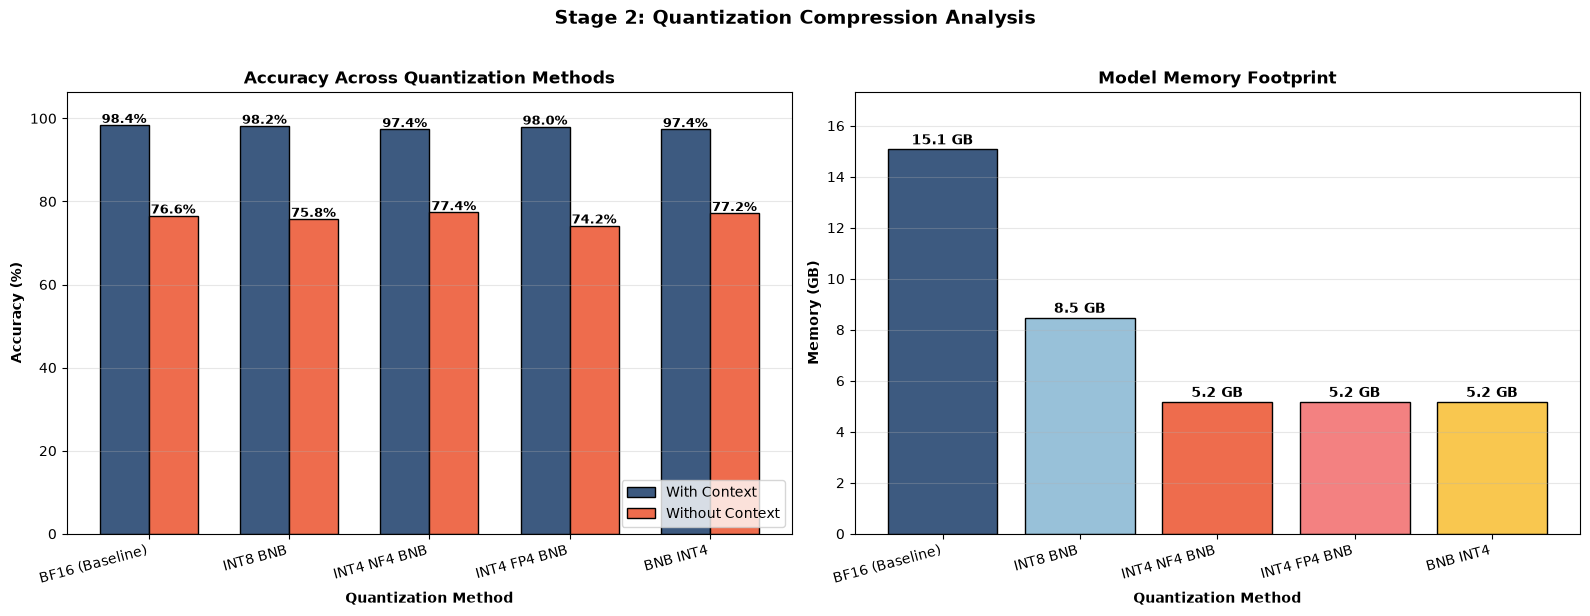


✅ Saved: results_jais_stage2/stage2_main_comparison.png


In [20]:
"""
Stage 2: Visualization of quantization compression results.
Reads JSON files from RESULTS_DIR and produces side-by-side accuracy and memory plots.
"""

import json
import os
import matplotlib.pyplot as plt
import numpy as np


# -------------------------------------------------------------------
# 1. Load results (same loader as load_stage2_results.py)
# -------------------------------------------------------------------
RESULTS_DIR = "results_jais_stage2"

RESULT_FILES = [
    ("BF16 (Baseline)", "baseline_bf16.json",  False),
    ("INT8 BNB",        "exp1_int8.json",      False),
    ("INT4 NF4 BNB",    "exp2_int4_nf4.json",  False),
    ("INT4 FP4 BNB",    "exp3_int4_fp4.json",  False),
    ("BNB INT4",        "exp4_bnb_int4.json",  False),
    ("GPTQ INT4",       "exp5_gptq_int4.json", True),
    ("AWQ INT4",        "exp6_awq_int4.json",  True),
]


def load_results(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


all_quantization_results = {}
for display_name, filename, optional in RESULT_FILES:
    path = os.path.join(RESULTS_DIR, filename)
    if not os.path.exists(path):
        if optional:
            continue
        raise FileNotFoundError(f"Required result file not found: {path}")
    all_quantization_results[display_name] = load_results(path)


# -------------------------------------------------------------------
# 2. Extract series for plotting
# -------------------------------------------------------------------
methods     = list(all_quantization_results.keys())
memory_gb   = [r["size_info"]["memory_gb"]         for r in all_quantization_results.values()]
with_ctx    = [r["with_context"]["accuracy"]       for r in all_quantization_results.values()]
without_ctx = [r["without_context"]["accuracy"]    for r in all_quantization_results.values()]

colors = ["#3D5A80", "#98C1D9", "#EE6C4D", "#F38181", "#F9C74F", "#4ECDC4", "#9D4EDD"]


# -------------------------------------------------------------------
# 3. Plot
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Accuracy comparison (grouped bars) ---
x = np.arange(len(methods))
width = 0.35
ax1 = axes[0]

bars1 = ax1.bar(x - width / 2, with_ctx,    width,
                label="With Context",    color="#3D5A80", edgecolor="black")
bars2 = ax1.bar(x + width / 2, without_ctx, width,
                label="Without Context", color="#EE6C4D", edgecolor="black")

for bar, val in zip(bars1, with_ctx):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{val:.1f}%", ha="center", fontsize=9, fontweight="bold")
for bar, val in zip(bars2, without_ctx):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{val:.1f}%", ha="center", fontsize=9, fontweight="bold")

ax1.set_xlabel("Quantization Method", fontweight="bold")
ax1.set_ylabel("Accuracy (%)", fontweight="bold")
ax1.set_title("Accuracy Across Quantization Methods", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(methods, rotation=15, ha="right")
# Headroom so the value labels don't get clipped
ax1.set_ylim(0, max(max(with_ctx), max(without_ctx)) + 8)
ax1.legend(loc="lower right")
ax1.grid(axis="y", alpha=0.3)

# --- Plot 2: Memory footprint ---
ax2 = axes[1]
bars = ax2.bar(x, memory_gb, color=colors[:len(methods)], edgecolor="black")

for bar, val in zip(bars, memory_gb):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
             f"{val:.1f} GB", ha="center", fontsize=10, fontweight="bold")

ax2.set_xlabel("Quantization Method", fontweight="bold")
ax2.set_ylabel("Memory (GB)", fontweight="bold")
ax2.set_title("Model Memory Footprint", fontweight="bold")
ax2.set_xticks(x)                                      # avoid the FixedLocator warning
ax2.set_xticklabels(methods, rotation=15, ha="right")
ax2.set_ylim(0, max(memory_gb) * 1.15)
ax2.grid(axis="y", alpha=0.3)

plt.suptitle("Stage 2: Quantization Compression Analysis",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

out_path = os.path.join(RESULTS_DIR, "stage2_main_comparison.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"\n✅ Saved: {out_path}")

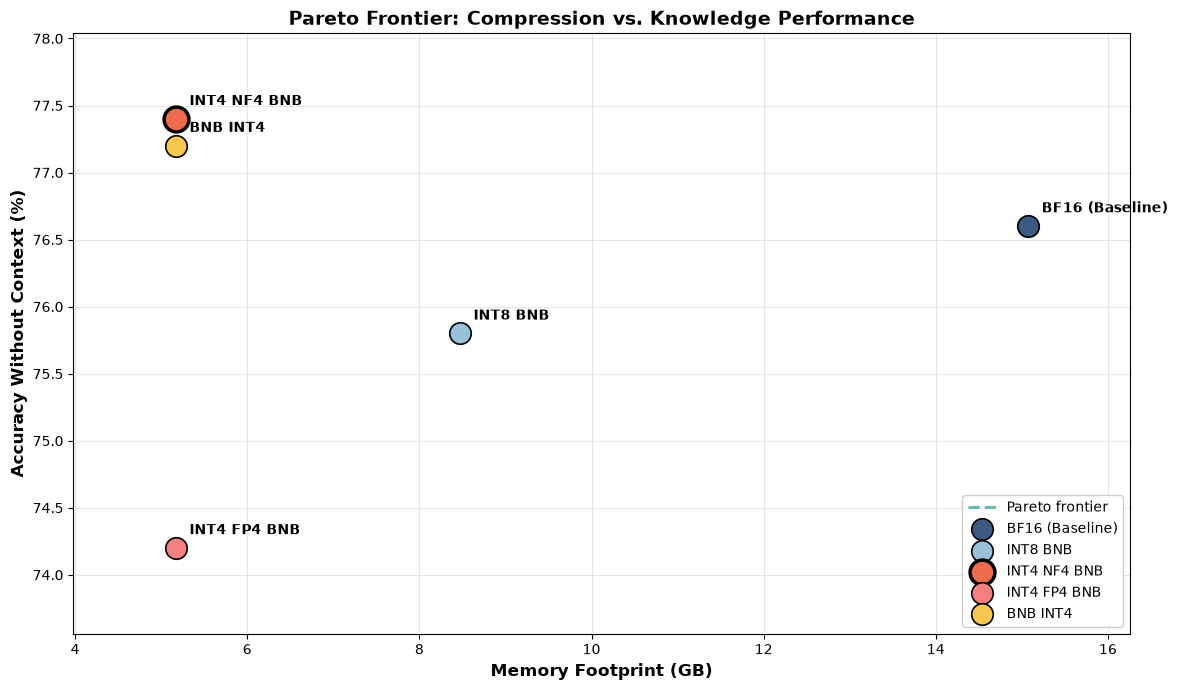

✅ Saved: results_jais_stage2/stage2_pareto_frontier.png
   Pareto-optimal methods: ['INT4 NF4 BNB']


In [21]:
"""
Stage 2 — Visualization 2: Pareto frontier (memory vs. knowledge performance).

Plots every method as a scatter point, draws a true Pareto frontier
(only non-dominated points, where no other method has both lower memory
AND higher accuracy), and uses adjustText to keep labels readable.
"""

import os
import matplotlib.pyplot as plt

# Assumes these are already in scope from the loader script:
#   methods, memory_gb, without_ctx, colors, RESULTS_DIR
# (If running standalone, paste the loader block from plot_stage2.py first.)


# -------------------------------------------------------------------
# 1. Compute the Pareto frontier (non-dominated set)
#    Objective: minimize memory, maximize accuracy.
#    A point is dominated if some other point has memory <= AND accuracy >=
#    with at least one strict inequality.
# -------------------------------------------------------------------
def pareto_indices(mem, acc):
    n = len(mem)
    dominated = [False] * n
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            if (mem[j] <= mem[i] and acc[j] >= acc[i] and
                (mem[j] < mem[i] or acc[j] > acc[i])):
                dominated[i] = True
                break
    return [i for i, d in enumerate(dominated) if not d]


pareto_idx = pareto_indices(memory_gb, without_ctx)
# Sort the frontier by memory so the connecting line is monotone
pareto_idx.sort(key=lambda i: memory_gb[i])
pareto_mem = [memory_gb[i] for i in pareto_idx]
pareto_acc = [without_ctx[i] for i in pareto_idx]


# -------------------------------------------------------------------
# 2. Plot
# -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

# Frontier line first (so points sit on top)
ax.plot(pareto_mem, pareto_acc, "--", color="#2A9D8F",
        linewidth=2.2, alpha=0.7, zorder=1, label="Pareto frontier")

# Scatter every method; highlight frontier members with a thicker ring
for i, method in enumerate(methods):
    on_frontier = i in pareto_idx
    ax.scatter(
        memory_gb[i], without_ctx[i],
        s=320 if on_frontier else 240,
        c=colors[i % len(colors)],
        edgecolor="black",
        linewidth=2.5 if on_frontier else 1.2,
        zorder=3,
        label=method,
    )

# Smart label placement (avoids overlap if package is available)
try:
    from adjustText import adjust_text
    texts = [
        ax.text(memory_gb[i], without_ctx[i], methods[i],
                fontsize=10, fontweight="bold")
        for i in range(len(methods))
    ]
    adjust_text(
        texts, ax=ax,
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.8),
        expand_points=(1.4, 1.4),
    )
except ImportError:
    # Fallback: simple offset annotations (may overlap when points cluster)
    for i, method in enumerate(methods):
        ax.annotate(
            method,
            xy=(memory_gb[i], without_ctx[i]),
            xytext=(10, 10), textcoords="offset points",
            fontsize=10, fontweight="bold",
        )

ax.set_xlabel("Memory Footprint (GB)", fontsize=12, fontweight="bold")
ax.set_ylabel("Accuracy Without Context (%)", fontsize=12, fontweight="bold")
ax.set_title("Pareto Frontier: Compression vs. Knowledge Performance",
             fontsize=14, fontweight="bold")

# Padding so labels don't get cut at the edges
x_pad = (max(memory_gb) - min(memory_gb)) * 0.12 or 1.0
y_pad = (max(without_ctx) - min(without_ctx)) * 0.20 or 1.0
ax.set_xlim(min(memory_gb) - x_pad, max(memory_gb) + x_pad)
ax.set_ylim(min(without_ctx) - y_pad, max(without_ctx) + y_pad)

ax.grid(True, alpha=0.3)
# De-duplicate legend entries (each method appears once + the frontier line)
handles, labels = ax.get_legend_handles_labels()
seen = set()
unique = [(h, l) for h, l in zip(handles, labels)
          if not (l in seen or seen.add(l))]
ax.legend([h for h, _ in unique], [l for _, l in unique],
          loc="lower right", fontsize=10, framealpha=0.95)

plt.tight_layout()

out_path = os.path.join(RESULTS_DIR, "stage2_pareto_frontier.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Saved: {out_path}")
print(f"   Pareto-optimal methods: {[methods[i] for i in pareto_idx]}")

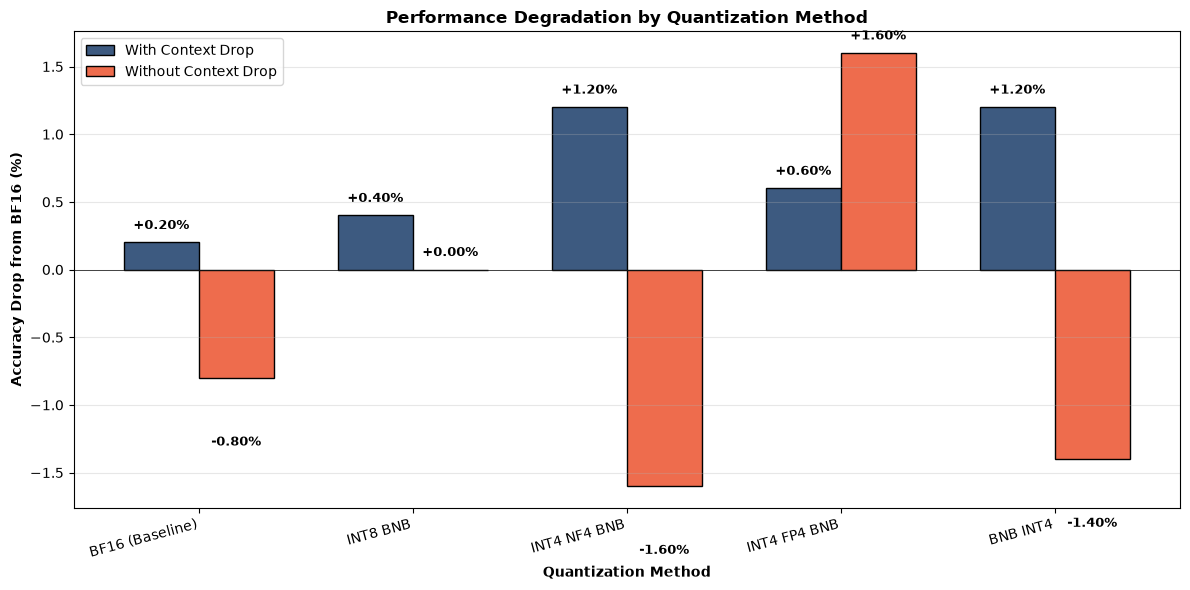

✅ Saved: ./results_jais_stage2/stage2_performance_drop.png


In [27]:
# Visualization 3: Performance Drop Analysis
fig, ax = plt.subplots(figsize=(12, 6))

baseline_with = baseline_results['with_context']['accuracy']
baseline_without = baseline_results['without_context']['accuracy']

drop_with = [(baseline_with - r['with_context']['accuracy']) for r in all_quantization_results.values()]
drop_without = [(baseline_without - r['without_context']['accuracy']) for r in all_quantization_results.values()]

x = np.arange(len(methods))
width = 0.35

bars1 = ax.bar(x - width/2, drop_with, width, label='With Context Drop', color='#3D5A80', edgecolor='black')
bars2 = ax.bar(x + width/2, drop_without, width, label='Without Context Drop', color='#EE6C4D', edgecolor='black')

for bar, val in zip(bars1, drop_with):
    ax.text(bar.get_x() + bar.get_width()/2, 
           bar.get_height() + (0.1 if bar.get_height() >= 0 else -0.5),
           f'{val:+.2f}%', ha='center', fontsize=9, fontweight='bold')
for bar, val in zip(bars2, drop_without):
    ax.text(bar.get_x() + bar.get_width()/2, 
           bar.get_height() + (0.1 if bar.get_height() >= 0 else -0.5),
           f'{val:+.2f}%', ha='center', fontsize=9, fontweight='bold')

ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xlabel('Quantization Method', fontweight='bold')
ax.set_ylabel('Accuracy Drop from BF16 (%)', fontweight='bold')
ax.set_title('Performance Degradation by Quantization Method', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=15, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'results_jais_stage2/stage2_performance_drop.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Saved: {Config.RESULTS_DIR}/stage2_performance_drop.png")

## 🏆 CELL 18: Final Stage 2 Report

In [13]:
"""
Stage 2 — Composite scoring: rank methods by (accuracy preservation × compression).
Assumes `all_quantization_results` is in scope from the loader.
"""

# ----- Pull baseline reference values FIRST -----
baseline_key     = "BF16 (Baseline)"
baseline_results = all_quantization_results[baseline_key]
baseline_info    = baseline_results["size_info"]
baseline_without = baseline_results["without_context"]["accuracy"]
baseline_with    = baseline_results["with_context"]["accuracy"]
baseline_mem_gb  = baseline_info["memory_gb"]

print("=" * 80)
print("Top Quantization Methods (Accuracy Preservation × Compression)")
print("=" * 80)
print(f"Baseline ({baseline_key}): {baseline_without:.2f}% "
      f"without-context, {baseline_mem_gb:.2f} GB\n")

scores = []
for method, results in all_quantization_results.items():
    if method == baseline_key:
        continue

    # Accuracy preservation: how much of baseline's knowledge is retained
    accuracy_pres = results["without_context"]["accuracy"] / baseline_without

    # Compression: fraction of memory saved relative to baseline
    compression = 1 - (results["size_info"]["memory_gb"] / baseline_mem_gb)

    # Composite: rewards methods that compress well AND preserve accuracy
    score = accuracy_pres * compression

    scores.append({
        "Method":            method,
        "Acc. Preservation": accuracy_pres,
        "Compression":       compression,
        "Score":             score,
    })

# Sort by score, descending
scores.sort(key=lambda r: r["Score"], reverse=True)

# Print ranking
print(f"{'Rank':<6}{'Method':<22}{'Acc.Pres.':<14}{'Compression':<14}{'Score':<10}")
print("-" * 66)
for rank, row in enumerate(scores, start=1):
    print(f"{rank:<6}{row['Method']:<22}"
          f"{row['Acc. Preservation']*100:>8.2f}%     "
          f"{row['Compression']*100:>8.2f}%     "
          f"{row['Score']:.4f}")

# Optional: save as DataFrame / CSV for the paper
import pandas as pd
import os

ranking_df = pd.DataFrame(scores).round(4)
out_path = os.path.join(RESULTS_DIR, "stage2_ranking.csv")
ranking_df.to_csv(out_path, index=False)
print(f"\n✅ Saved ranking to: {out_path}")
print(f"\n🏆 Best method: {scores[0]['Method']} (score = {scores[0]['Score']:.4f})")

Top Quantization Methods (Accuracy Preservation × Compression)
Baseline (BF16 (Baseline)): 79.20% without-context, 16.36 GB

Rank  Method                Acc.Pres.     Compression   Score     
------------------------------------------------------------------
1     INT4 NF4 BNB            100.25%        71.07%     0.7125
2     INT4 FP4 BNB            100.00%        71.07%     0.7107
3     BNB INT4                 99.49%        71.07%     0.7071
4     INT8 BNB                100.25%        47.38%     0.4750

✅ Saved ranking to: results_stage2/stage2_ranking.csv

🏆 Best method: INT4 NF4 BNB (score = 0.7125)


## 🎉 STAGE 2 COMPLETE!

### What You've Accomplished:

1. ✅ Loaded SFT teacher model (Stage 1 best)
2. ✅ Established BF16 baseline
3. ✅ Tested INT8 quantization (~50% compression)
4. ✅ Tested INT4 NF4 quantization (~75% compression)
5. ✅ Tested INT4 FP4 quantization (alternative)
6. ✅ Tested GPTQ INT4 (optimized)
7. ✅ Tested AWQ INT4 (if available)
8. ✅ Generated Pareto frontier analysis
9. ✅ Created publication-ready tables and figures

### Files Ready for Paper:
- `stage2_comparison.csv` - Main results table
- `stage2_main_comparison.png` - Bar chart
- `stage2_pareto_frontier.png` - Pareto plot
- `stage2_performance_drop.png` - Degradation analysis
- `stage2_final_report.txt` - Text report
- `stage2_all_results.json` - All data

### Next Steps:
1. **Analyze results** - identify patterns
2. **Write paper** sections using these results
3. **(Optional) Stage 3**: Knowledge Distillation for smaller models
4. **(Optional) Stage 4**: Combined compression methods